<a href="https://colab.research.google.com/github/id1557/deep-learning/blob/main/Tensorflow_Clasificacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><font color="#113D68" size=5>Redes neuronales y deep learning</font></h1>



<h1><font color="#113D68" size=6>Mi segunda red neuronal con TensorFlow: <br>Clasificación</font></h1>


<br><br>
<div style="text-align: right">
<font size=3>Daniel González</font><br>
<font size=3>Semana 2: Frameworks de Deep Learning: TensorFlow</font><br>
<font size=3>IEBS</font>
</div>

---

<a id="indice"></a>
<h2><font color="#004D7F" size=5>Índice</font></h2>

* [Problema de clasificación](#section1)
    * [MNIST Dataset](#section1.1)
    * [Preparar datos de entrenamiento](#section1.2)
    * [Construir la red](#section1.3)
    * [Entrenamiento](#section1.4)
    * [Evaluar modelo](#section1.5)
    * [Realizar predicciones](#section1.6)

In [1]:
import tensorflow as tf
import numpy as np

# Para mostrar gráficas
import matplotlib.pyplot as plt
%matplotlib inline

# Para mostrar imágenes en python
from PIL import Image

# Anaconda fixing problem
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

<a id="section2"></a>
# <font color="#004D7F" size=5>Problema de clasificación</font>

En el problema anterior hemos visto como construir una red neuronal con una sola capa, a continuación veremos un problema de clasificación que resolveremos con un red neuronal multicapa donde usaremos funciones de activación no lineales. La ventaja de añadir capas ocultas a una red es que permite resolver problemas más complejos.

<a id="section2.1"></a>
# <font color="#004D7F" size=4>MNIST dataset</font>

En este problema usaremos la base de datos de imágenes MNIST, que está compuesta por imágenes de números escritos a mano del 0 al 9. El propósito de este problema será construir una red neuronal multicapa donde la entrada de los datos será una imagen y la salida será el número que hay en esa imagen.

<a id="section2.2"></a>
# <font color="#004D7F" size=4>Preparar datos de entrenamiento</font>
Para empezar debemos descargar los datos. Tensorflow viene con varios ejemplos de bases de datos que poder utilizar, MNIST es uno de ellos, por lo que podemos descargarlo directamente con Tensorflow:

In [2]:
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Vamos a mostrar una pequeña muestra de las imágenes:

In [3]:
def show_images(images, gray=True):
    fig=plt.figure(figsize=(8, 8))
    index = np.random.randint(len(images), size=100)
    for i in range(100):
        fig.add_subplot(10, 10, i+1)
        plt.axis('off')
        if gray:
            color = 'gray'
        else:
            color = None
        plt.imshow(images[index[i]].reshape([28, 28]), cmap=color)
    plt.show()

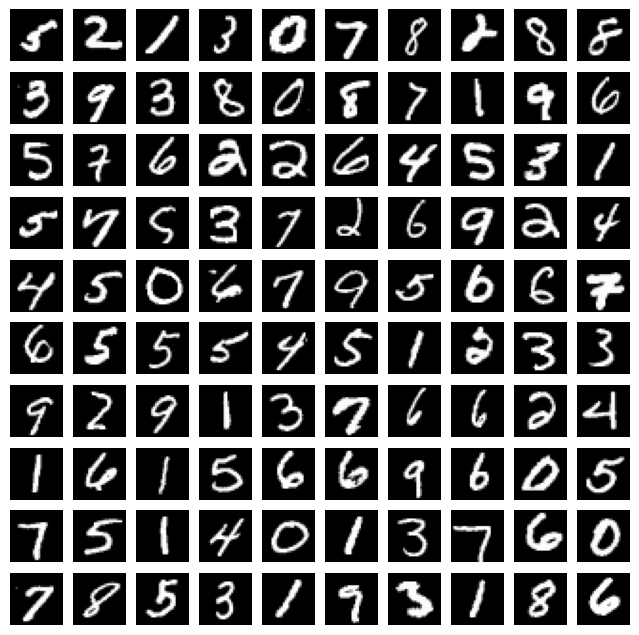

In [4]:
show_images(x_train)

Las imágenes son de tamaño 28x28 pixeles y en blanco y negro. Podemos observar cómo tenemos distintos números y al ser escritos a mano tienen formas distintas, por lo que será un reto para nuestra red poder aprender a diferencia entre números y aprender que números son los mismos.

Las imágen son _arrays_ de _numpy_ por lo que podemos tratarlas como tal y usar los atributos y funciones que tienen, como el atributo `shape`.

A continuación, vamos a ver más detalles de los datos de entrada.

In [5]:
print("Num training images: ", x_train.shape[0])
print("Num test images: ", x_test.shape[0])
print("Dimension input: ", x_train.shape)
print("Dimension output: ", y_train.shape)
print("Output example: ", y_train[0])

Num training images:  60000
Num test images:  10000
Dimension input:  (60000, 28, 28)
Dimension output:  (60000,)
Output example:  5


In [6]:
y_train[1]

np.uint8(0)

Al ser las imágenes en blanco y negro, cada pixel tiene un valor entre el 0 y el 255, siendo 0 el negro y 255 el blanco. Veamos los valores completos de una imágen:

In [7]:
img = x_train[0]
print("Valores de una imágen:")
print(img)

Valores de una imágen:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253

La imagen que estamos viendo es la siguiente:

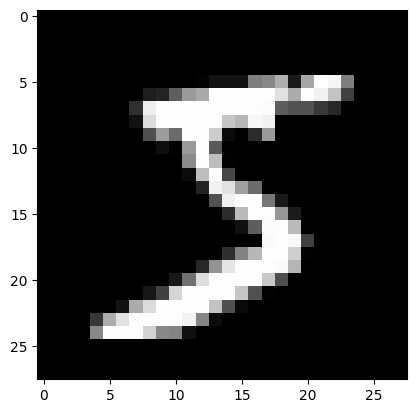

In [8]:
plt.imshow(x_train[0], cmap='gray')
plt.show()

Para ver el valor de `y` de esta imagen podemos acceder a su correspondiente valor:

In [9]:
y_train[0]

np.uint8(5)

> **Nota**: al ser los valores entre el 0 y el 255, para que el resultado del entrenamiento sea más óptimo es preferible **normalizar** estos valores entre 0 y 1. Se puede realizar de la siguiente forma:

In [10]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [11]:
x_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

<a id="section2.2"></a>
# <font color="#004D7F" size=4>Construir la red</font>

Empecemos definiendo la entrada y la salida de los datos de nuestra red:

* La **entrada** de los datos serán las imágenes que son de dimensiones 28x28 pixeles, que en total son $28x28 = 784$ valores del 0 al 1 ya que son imágenes en blanco y negro normalizadas. Por lo tanto, la entrada de nuestra red será de dimensión 784 (28x28).
* La **salida** de nuestra red será la predicción del número que hay en la imagen. Como tenemos dígitos del 0 al 9 la dimensión de la salida de la red será de dimensión 10 por cada categoría, donde cada valor será la probabilidad de dicho número. La categoría con la probabilidad más alta, será el número que nuestra red clasifique.

A continuación tenemos que definir los pesos, los sesgos y la arquitectura de nuestra red. La red que vamos a definir tendrá la siguiente arquitectura:

<br>
<div align="center">
<img src="https://drive.google.com/uc?id=11i8gSbswwgd3u_rB_Nfkh2EZoefL0hnK" width="700">
</div>
<br>

Arquitectura de la red:

* **1º capa**: será una capa oculta que usará una función de activación no lineal *ReLU*. La función *ReLU* devuelve 0 para valores negativos y $x$ para todo $x > 0$.
* **2º capa**: será una capa oculta que también usará una función de activación no lineal *ReLU*.
* **3º capa**: será una capa de salida que usará una función de activación para clasificar *Softmax*. La función *Softmax* devuleve valores entre 0 y 1 normalizados, de manera que todos los valores que devuelve sumen 1.

<br>

<div align="center">
<div class="col-sm-6">
<img src="https://drive.google.com/uc?id=15i8xytSCF5RMzUSMl7mlvjajz6DOdwoV" width="250">
</div>

<div class="col-ms-6">
<img src="https://drive.google.com/uc?id=1gOXKIQTgy6FG75wEC36BJA2ctYGD3q9p" width="250">
</div>
</div>

Para definir el tipo de función de activación que tendrá cada capa, a la hora de definir la capa podemos definir en el argumento `activation` el tipo de función que es. La funciones de activación que ofrece TensorFlow son las siguiente: https://www.tensorflow.org/api_docs/python/tf/keras/activations.

In [12]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(64, activation='relu'),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.summary()

<a id="section2.4"></a>
# <font color="#004D7F" size=4>Entrenamiento</font>
Una vez que ya tenemos nuestra red definida, configuraremos el entrenamiento. En la configuración definiremos:

- `optimizer`: usaremos el optimizador `adam` y cambiaremos el `learning rate`.
- `loss`: usaremos como función de coste *Sparse Categorical Crossentropy* ya que es un problema de clasificación y la salida está con etiquetas del 0 al 9.
- `metrics`: al ser un problema de clasificación esta vez evaluaremos la precision del modelo.
- `batch_size`: estableceremos un tamaño de *batch* de 128.
- `epochs`: estableceremos el número de *epochs* em 10.

In [13]:
# Definimos el optimizador cambiando el factor de entrenamiento
opt = tf.keras.optimizers.Adam(learning_rate=0.001)

# Compilamos el modelo
model.compile(optimizer=opt,
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [14]:
hist = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9218 - loss: 0.2685 - val_accuracy: 0.9582 - val_loss: 0.1354
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9647 - loss: 0.1165 - val_accuracy: 0.9673 - val_loss: 0.1042
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9736 - loss: 0.0838 - val_accuracy: 0.9685 - val_loss: 0.1025
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9792 - loss: 0.0662 - val_accuracy: 0.9721 - val_loss: 0.0881
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9827 - loss: 0.0536 - val_accuracy: 0.9741 - val_loss: 0.0854
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9853 - loss: 0.0450 - val_accuracy: 0.9728 - val_loss: 0.0915
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9875 - loss: 0.0373 - val_accuracy: 0.9700 - val_loss: 0.1110
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9891 - loss: 0.0328 -

En la salida, podemos comprabar cómo la red aprende con cada *epoch* reduciento el error al predecir y aumentando la precisión en la predicción. Si cambiásemos la configuración o las capas de nuestra red, el entrenamiento sería distinto, podría tardar más o incluso podría no llegar a aprender.

<a id="section2.5"></a>
# <font color="#004D7F" size=4>Evaluar modelo</font>

A continuación vamos a evaluar como de bien funciona el modelo visualizando el error y la precisión.

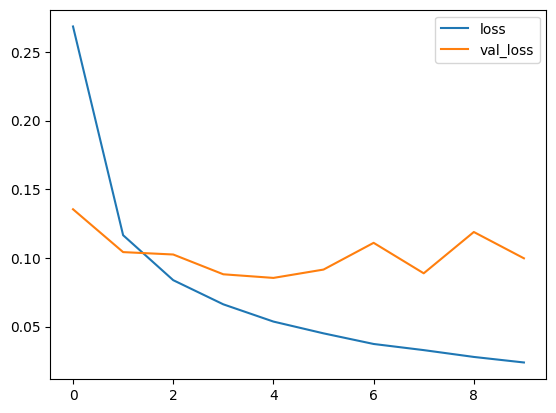

In [15]:
plt.plot(hist.history['loss'], label='loss')
plt.plot(hist.history['val_loss'], label='val_loss')
plt.legend()

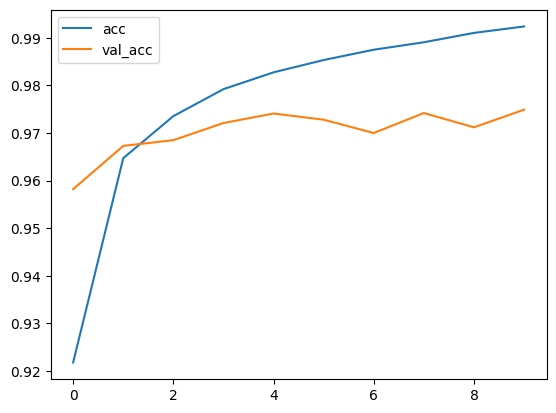

In [16]:
plt.plot(hist.history['accuracy'], label='acc')
plt.plot(hist.history['val_accuracy'], label='val_acc')
plt.legend()

Podemos observar como se comporta el modelo con los casos de test:

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step


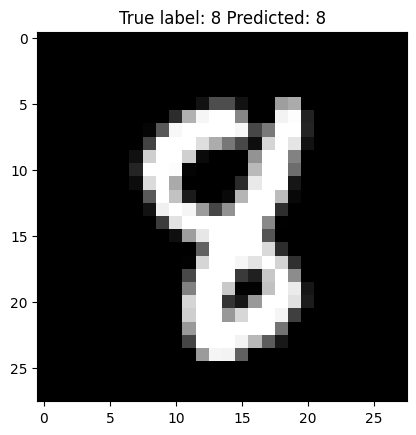

In [17]:
# Cogemos un indice al azar y su prediccion
i = np.random.choice(range(0,x_test.shape[0]))
prediction = model.predict(np.array([x_test[i]])).argmax(axis=1)[0]

plt.imshow(x_test[i], cmap='gray')
plt.title("True label: %s Predicted: %s" % (y_test[i], prediction));

Podemos mostrar algunos falsos positivos para ver donde falla nuestro modelo:

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


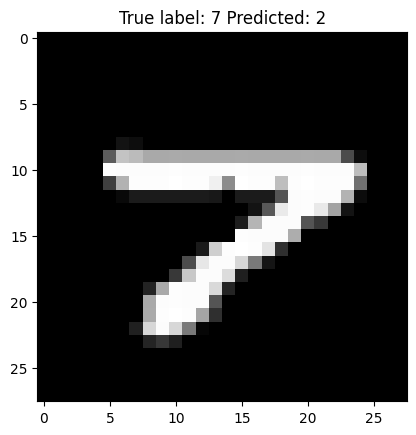

In [18]:
# Obtenemos las predicciones del conjunto de test
p_test = model.predict(x_test).argmax(axis=1)

# Filtramos cogiendo las predicciones erroneas
misclassified_idx = np.where(p_test != y_test)[0]

# Cogemos un indice al azar
i = np.random.choice(misclassified_idx)

plt.imshow(x_test[i], cmap='gray')
plt.title("True label: %s Predicted: %s" % (y_test[i], p_test[i]));

<a id="section2.6"></a>
# <font color="#004D7F" size=4>Realizar predicciones</font>

A continuación vamos a realizar predicciones:

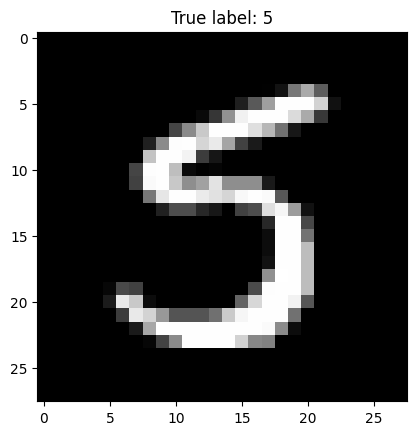

In [19]:
# seleccionamos un número al azar del conjunto de train
i = np.random.choice(range(0,x_test.shape[0]))
number = x_test[i]
plt.imshow(number, cmap='gray')
plt.title("True label: %s" % y_test[i]);

Pasamos ese número a nuestro modelo entrenado para ver que salida tiene:

In [20]:
# realizamos la predicción
prediction = model.predict(np.array([number]))
prediction

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


array([[9.8668306e-19, 7.1858938e-12, 2.2821413e-17, 1.0362457e-08,
        1.2068992e-20, 1.0000000e+00, 2.0547941e-17, 3.4627827e-16,
        1.4475874e-14, 3.5295036e-09]], dtype=float32)

La salida es una lista de tamaño 10, donde cada valor es la probabilidad. El índice con la probabilidad más alta será la predicción realizada por nuestro modelo:

In [21]:
# cogemos el índice con la probabilidad más alta
prediction_order = prediction.argmax(axis=1)
prediction_order

array([5])

Hasta aquí hemos visto cómo construir una red neuronal en Tensorflow y cómo añadirle varias capas ocultas. Si quisiéramos construir modelos más complejos tendríamos que incluir más capas ocultas y combinarlo con varias funciones de activación, de esta forma construiríamos redes neurnoales profundas.

<div align="center">
<img src="https://drive.google.com/uc?id=1PL-Lq3eWzHYo0J1sH-adNwDggdrZejOP" width="700">
</div>